## Cell 1: csv -> h5
## Cell 2: CNN architecture and training
## Cell 3: CNN validation on specific samples

In [ ]:
import os
import h5py
import pandas as pd
import numpy as np
from tqdm import tqdm

# --- ŚCIEŻKI ---
METADATA_PATH = r'C:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\CNN_reg\50k_dataset\metadata.csv'
SPECTRA_DIR = r'C:\Users\Ja\Desktop\Studia\Studia 4 sem\pracownia\CNN_reg\50k_dataset\para1'

OUTPUT_HDF5 = 'libs_dataset.h5'
CLEANED_METADATA_PATH = 'metadata_cleaned.csv'

WAVELENGTH_MIN = 200.0
WAVELENGTH_MAX = 1000.0
GRID_STEP = 0.05

print("Wczytywanie metadanych...")
df_meta = pd.read_csv(METADATA_PATH)

target_columns = df_meta.columns[1:] 
num_samples = len(df_meta)

master_wavelengths = np.round(np.arange(WAVELENGTH_MIN, WAVELENGTH_MAX + (GRID_STEP / 2), GRID_STEP), decimals=2).astype(np.float32)
num_features = len(master_wavelengths)

print(f"Liczba zaplanowanych próbek: {num_samples}")

# Zmienne do śledzenia prawidłowych plików
valid_indices = []
valid_count = 0

print(f"Tworzenie pliku {OUTPUT_HDF5}...")
with h5py.File(OUTPUT_HDF5, 'w') as h5f:
    
    X_dataset = h5f.create_dataset('spectra', shape=(num_samples, num_features), maxshape=(None, num_features), dtype='float32')
    y_dataset = h5f.create_dataset('concentrations', shape=(num_samples, len(target_columns)), maxshape=(None, len(target_columns)), dtype='float32')
    h5f.create_dataset('wavelengths', data=master_wavelengths)
    
    for i, row in tqdm(df_meta.iterrows(), total=num_samples, desc="Zapisywanie widm"):
        filename = row['sample_id']
        filepath = os.path.join(SPECTRA_DIR, filename)
        
        try:
            spectrum_df = pd.read_csv(filepath)
            
            # Jeśli wczytany DataFrame jest z jakiegoś powodu pusty - pomijamy
            if spectrum_df.empty or 'wavelength' not in spectrum_df.columns:
                continue
                
        except pd.errors.EmptyDataError:
            # ŁAPIEMY BŁĄD PUSTEGO PLIKU: Po prostu przechodzimy do następnego
            continue
        except Exception:
            # Inne błędy odczytu również ignorujemy
            continue
            
        spectrum_df['wavelength'] = pd.to_numeric(spectrum_df['wavelength'], errors='coerce')
        spectrum_df['intensity'] = pd.to_numeric(spectrum_df['intensity'], errors='coerce')
        spectrum_df = spectrum_df.dropna().sort_values('wavelength')
        
        if spectrum_df.empty:
            continue
            
        current_wavelengths = spectrum_df['wavelength'].values.astype(np.float32)
        current_intensities = spectrum_df['intensity'].values.astype(np.float32)
        
        interpolated_intensities = np.interp(
            master_wavelengths, 
            current_wavelengths, 
            current_intensities,
            left=0, right=0
        )
        
        min_val = np.min(interpolated_intensities)
        max_val = np.max(interpolated_intensities)
        if max_val > min_val:
            interpolated_intensities = (interpolated_intensities - min_val) / (max_val - min_val)
            
        # Zapisujemy do aktualnie "ważnego" wiersza
        X_dataset[valid_count, :] = interpolated_intensities
        
        # Zapisujemy stężenia do odpowiedniego wiersza
        targets = row[target_columns].values.astype(np.float32)
        y_dataset[valid_count, :] = targets
        
        # Zapisujemy indeks z df_meta, żeby wiedzieć, które pliki przetrwały
        valid_indices.append(i)
        valid_count += 1

    # --- NA KONIEC: Przycinanie macierzy ---
    print(f"\nUkończono! Sukcesem zakończono odczyt {valid_count} z {num_samples} plików.")
    
    # Skracamy macierze HDF5, ucinając puste miejsce po zepsutych plikach
    X_dataset.resize((valid_count, num_features))
    y_dataset.resize((valid_count, len(target_columns)))

# Wycinamy tylko te wiersze z metadanych, które odpowiadają zdrowym widmom i zapisujemy nowy plik
df_meta_cleaned = df_meta.iloc[valid_indices]
df_meta_cleaned.to_csv(CLEANED_METADATA_PATH, index=False)
print(f"Zapisano czyste metadane: {CLEANED_METADATA_PATH}")

Wczytywanie metadanych...
Liczba zaplanowanych próbek: 51344
Tworzenie pliku libs_dataset.h5...


Zapisywanie widm: 100%|██████████| 51344/51344 [14:58<00:00, 57.16it/s]



Ukończono! Sukcesem zakończono odczyt 51332 z 51344 plików.
Zapisano czyste metadane: metadata_cleaned.csv


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import h5py
import numpy as np

# --- 1. USTAWIENIA ---
HDF5_PATH = 'libs_dataset.h5'
BATCH_SIZE = 512 
EPOCHS = 50
LEARNING_RATE = 0.0005  

# --- 2. KLASA DATASET (Z HDF5) ---
class LIBSDatasetHDF5(Dataset):
    def __init__(self, hdf5_path):
        self.hdf5_path = hdf5_path
        with h5py.File(self.hdf5_path, 'r') as f:
            self.length = f['spectra'].shape[0]
            self.input_dim = f['spectra'].shape[1]       
            self.num_elements = f['concentrations'].shape[1] 
        self.h5f = None

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        if self.h5f is None:
            self.h5f = h5py.File(self.hdf5_path, 'r')
        
        x = self.h5f['spectra'][idx]
        y = self.h5f['concentrations'][idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

# --- 3. ARCHITEKTURA SIECI 1D CNN (V2) ---
class LIBS_1D_CNN(nn.Module):
    def __init__(self, input_dim, num_elements):
        super(LIBS_1D_CNN, self).__init__()
        
        self.conv_layers = nn.Sequential(

            # Conv1d z kernel_size=7, na starcie: Szeroki filtr pozwala "zauwazyc" ca;e szerokie piki i ich otoczenie
            
            nn.Conv1d(1, 32, kernel_size=7, stride=1, padding=3),
            
            # BarchNorm1d: Zapobiega problemowi "eksplodujacych" gradientow

            nn.BatchNorm1d(32),
            nn.ReLU(),

            # MaxPoll1d: Redukuje wymiarowosc, zachowujac wazne cechy widma

            nn.MaxPool1d(kernel_size=2),
            
            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Obliczony dynamiczne, 
        self.flattened_size = 128 * (input_dim // 8) 
        
        self.fc_layers = nn.Sequential(
            nn.Linear(self.flattened_size, 512),
            nn.ReLU(),

            # Dropout: Zmniejsza przeuczenie sieci

            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_elements)
        )

    def forward(self, x):
        x = x.unsqueeze(1) # Dodajemy kanał do konwolucji: wymagane
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1) # Spłaszczamy
        x = self.fc_layers(x)
        
        # Wymuszamy, by wyniki były zawsze dodatnie i sumowały się równo do 100%
        x = torch.softmax(x, dim=1) * 100.0
        
        return x

# --- 4. GŁÓWNA PĘTLA TRENINGOWA ---
def main():
    print("Ładowanie zbioru danych...")
    dataset = LIBSDatasetHDF5(HDF5_PATH)
    
    print(f"Całkowita liczba próbek: {len(dataset)}")
    print(f"Długość widma: {dataset.input_dim}")
    print(f"Liczba przewidywanych pierwiastków: {dataset.num_elements}")

    # Podział 80% Trening, 20% Walidacja
    train_size = int(0.8 * len(dataset))
    val_size = len(dataset) - train_size
    train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

    # Zostawiamy num_workers=0 (ochrona przed deadlockiem w Windows), dodajemy pin_memory=True - przyspiesza kopiowanie danych z RAM do VRAM
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

    # Przygotowanie urządzenia i modelu
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\nTrening uruchomiony na: {device}")
    
    model = LIBS_1D_CNN(input_dim=dataset.input_dim, num_elements=dataset.num_elements).to(device)
    
    criterion = nn.MSELoss() 
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
    # Scheduler: Zmniejsza Learning Rate o połowę, jeśli Val Loss nie spada przez 3 epoki
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    best_val_loss = float('inf')

    # Trening właściwy
    for epoch in range(EPOCHS):
        model.train()
        running_train_loss = 0.0
        
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * inputs.size(0)
            
        epoch_train_loss = running_train_loss / len(train_dataset)
        
        # Walidacja
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_val_loss += loss.item() * inputs.size(0)
                
        epoch_val_loss = running_val_loss / len(val_dataset)
        
        # Pobieranie aktualnego Learning Rate, aby widzieć działanie schedulera
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"Epoka {epoch+1:02d}/{EPOCHS} | Train Loss (MSE): {epoch_train_loss:.2f} | Val Loss: {epoch_val_loss:.2f} | LR: {current_lr:.6f}")

        # Krok schedulera - na podstawie błędu walidacji
        scheduler.step(epoch_val_loss)

        # Zapis modelu
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), 'best_libs_model_1.pth')

    print("\nZakończono! Najlepszy, ustabilizowany model został zapisany jako 'best_libs_model.pth'.")

if __name__ == '__main__':
    main()

Ładowanie zbioru danych...
Całkowita liczba próbek: 51332
Długość widma: 16001
Liczba przewidywanych pierwiastków: 10

Trening uruchomiony na: cuda
Epoka 01/50 | Train Loss (MSE): 207.54 | Val Loss: 750.22 | LR: 0.000500
Epoka 02/50 | Train Loss (MSE): 52.04 | Val Loss: 209.19 | LR: 0.000500
Epoka 03/50 | Train Loss (MSE): 28.13 | Val Loss: 866.59 | LR: 0.000500
Epoka 04/50 | Train Loss (MSE): 20.84 | Val Loss: 214.06 | LR: 0.000500
Epoka 05/50 | Train Loss (MSE): 17.99 | Val Loss: 102.58 | LR: 0.000500
Epoka 06/50 | Train Loss (MSE): 14.91 | Val Loss: 460.03 | LR: 0.000500
Epoka 07/50 | Train Loss (MSE): 12.69 | Val Loss: 327.13 | LR: 0.000500
Epoka 08/50 | Train Loss (MSE): 12.00 | Val Loss: 47.33 | LR: 0.000500
Epoka 09/50 | Train Loss (MSE): 10.58 | Val Loss: 41.52 | LR: 0.000500
Epoka 10/50 | Train Loss (MSE): 10.62 | Val Loss: 165.34 | LR: 0.000500
Epoka 11/50 | Train Loss (MSE): 9.18 | Val Loss: 422.74 | LR: 0.000500
Epoka 12/50 | Train Loss (MSE): 8.54 | Val Loss: 57.80 | LR: 0

Ładowanie danych i modelu...


C:\Users\Ja\AppData\Local\Temp\ipykernel_37284\552866362.py:93: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_PATH, map_location=devic

Pomyślnie załadowano wagi z pliku: best_libs_model_1.pth

--- Próbka 32393 ---
Mg: Prawdziwe =   0.00%, Przewidziane =   0.20%
Fe: Prawdziwe =   0.00%, Przewidziane =   0.08%
Mn: Prawdziwe =   0.00%, Przewidziane =   0.08%
Al: Prawdziwe =   0.00%, Przewidziane =   0.01%
Zn: Prawdziwe =   0.00%, Przewidziane =   0.21%
C: Prawdziwe =   0.00%, Przewidziane =   0.32%
N: Prawdziwe =  24.92%, Przewidziane =  24.25%
Si: Prawdziwe =   0.00%, Przewidziane =   0.05%
Ni: Prawdziwe =   0.00%, Przewidziane =   0.11%
Cu: Prawdziwe =  75.08%, Przewidziane =  74.68%

--- Próbka 5626 ---
Mg: Prawdziwe =  32.53%, Przewidziane =  34.18%
Fe: Prawdziwe =   0.00%, Przewidziane =   0.04%
Mn: Prawdziwe =   0.00%, Przewidziane =   0.07%
Al: Prawdziwe =   0.00%, Przewidziane =   0.12%
Zn: Prawdziwe =   0.00%, Przewidziane =   0.08%
C: Prawdziwe =  12.90%, Przewidziane =  12.73%
N: Prawdziwe =  54.57%, Przewidziane =  52.39%
Si: Prawdziwe =   0.00%, Przewidziane =   0.24%
Ni: Prawdziwe =   0.00%, Przewidziane = 

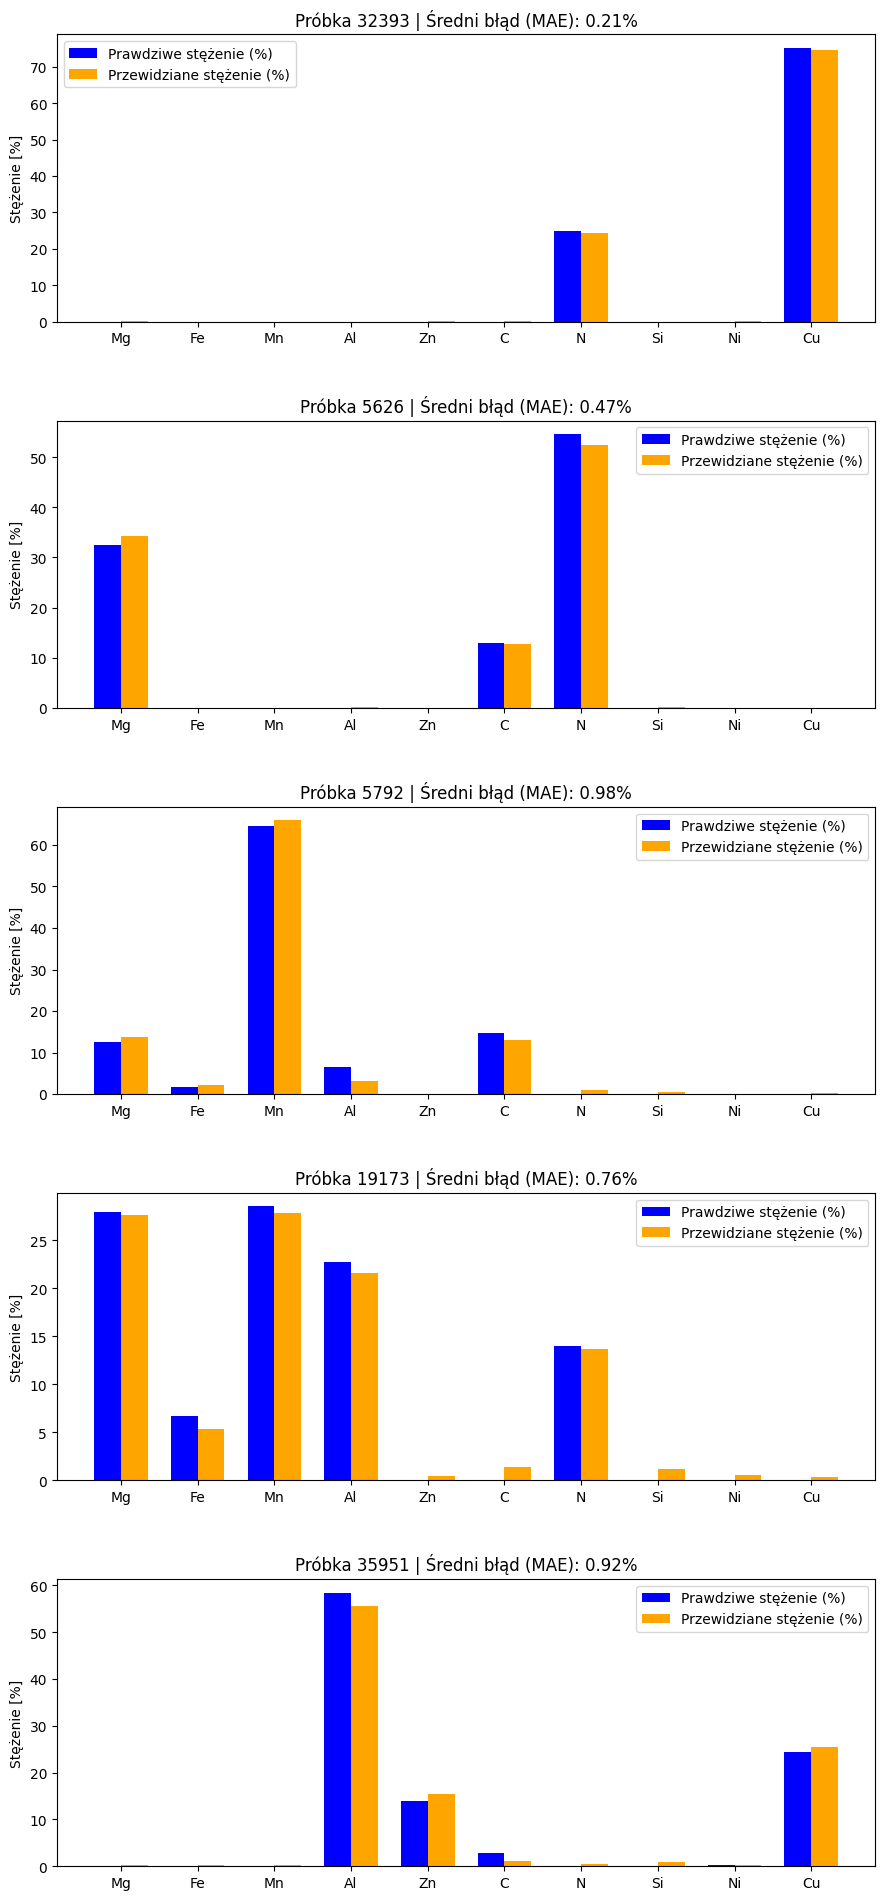

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset
import h5py
import numpy as np
import random
import matplotlib.pyplot as plt

# --- 1. USTAWIENIA ---
HDF5_PATH = 'libs_dataset.h5'
MODEL_PATH = 'best_libs_model_1.pth'

ELEMENTS = ["Mg", "Fe", "Mn", "Al", "Zn", "C", "N", "Si", "Ni", "Cu"] 

# --- 2. KLASY ---
class LIBSDatasetHDF5(Dataset):
    def __init__(self, hdf5_path):
        self.hdf5_path = hdf5_path
        with h5py.File(self.hdf5_path, 'r') as f:
            self.length = f['spectra'].shape[0]
            self.input_dim = f['spectra'].shape[1]       
            self.num_elements = f['concentrations'].shape[1] 
        self.h5f = None

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        if self.h5f is None:
            self.h5f = h5py.File(self.hdf5_path, 'r')
        
        x = self.h5f['spectra'][idx]
        y = self.h5f['concentrations'][idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

class LIBS_1D_CNN(nn.Module):
    def __init__(self, input_dim, num_elements):
        super(LIBS_1D_CNN, self).__init__()
        
        self.conv_layers = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, stride=1, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            
            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        self.flattened_size = 128 * (input_dim // 8) 
        
        self.fc_layers = nn.Sequential(
            nn.Linear(self.flattened_size, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_elements)
        )

    def forward(self, x):
        x = x.unsqueeze(1) 
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1) 
        x = self.fc_layers(x)
        
        
        x = torch.softmax(x, dim=1) * 100.0
        
        return x

# --- 3. GŁÓWNA LOGIKA TESTUJĄCA ---
def main():
    print("Ładowanie danych i modelu...")
    dataset = LIBSDatasetHDF5(HDF5_PATH)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    model = LIBS_1D_CNN(dataset.input_dim, dataset.num_elements).to(device)
    
    # Ładowanie zapisanych wag
    try:
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        print(f"Pomyślnie załadowano wagi z pliku: {MODEL_PATH}")
    except Exception as e:
        print(f"Błąd ładowania modelu: {e}")
        return

    model.eval() # Tryb ewaluacji (wyłącza Dropout)

    # Losowanie 5 indeksów z całego zbioru
    random_indices = random.sample(range(len(dataset)), 5)
    
    fig, axes = plt.subplots(5, 1, figsize=(10, 20))
    fig.tight_layout(pad=5.0)

    for i, idx in enumerate(random_indices):
        x, y_true = dataset[idx]
        
        # Dodajemy wymiar batcha (1, 16001)
        x_input = x.unsqueeze(0).to(device) 
        
        with torch.no_grad():
            y_pred = model(x_input).squeeze().cpu().numpy()
            
        y_true = y_true.numpy()
        
        # Zabezpieczenie przed ujemnymi przewidywaniami (stężenie nie może być < 0)
        y_pred = np.maximum(y_pred, 0.0)
        
        # Obliczenie błędu MAE dla tej próbki
        mae = np.mean(np.abs(y_true - y_pred))
        
        print(f"\n--- Próbka {idx} ---")
        for el, true_val, pred_val in zip(ELEMENTS, y_true, y_pred):
            print(f"{el}: Prawdziwe = {true_val:>6.2f}%, Przewidziane = {pred_val:>6.2f}%")
            
        # Rysowanie wykresu
        ax = axes[i]
        x_pos = np.arange(len(ELEMENTS))
        width = 0.35
        
        ax.bar(x_pos - width/2, y_true, width, label='Prawdziwe stężenie (%)', color='blue')
        ax.bar(x_pos + width/2, y_pred, width, label='Przewidziane stężenie (%)', color='orange')
        
        ax.set_ylabel('Stężenie [%]')
        ax.set_title(f'Próbka {idx} | Średni błąd (MAE): {mae:.2f}%')
        ax.set_xticks(x_pos)
        ax.set_xticklabels(ELEMENTS)
        ax.legend()

    plt.show()

if __name__ == '__main__':
    main()